###Data Preprocessing and cleaning

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
%reload_ext google.colab.data_table
import pandas as pd
df=pd.read_csv('/content/screentime.csv')
df

Output hidden; open in https://colab.research.google.com to view.

In [3]:
df.describe()

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,34.355647,59.250000,55.153882,0.467765,33.222471,35.701412,40.671471,6.266209,21.735741,19.105859,2.766000,3.794671
std,11.584259,36.931991,19.850550,0.498989,51.935645,20.819390,17.444914,1.446258,3.069377,2.546459,1.695407,2.685153
min,18.000000,1.000000,10.000000,0.000000,0.000000,0.000000,6.000000,3.200000,8.100000,9.600000,0.000000,1.000000
25%,25.000000,31.000000,42.000000,0.000000,0.000000,21.000000,28.200000,5.240000,19.700000,17.400000,2.000000,1.100000
50%,32.000000,51.000000,55.000000,0.000000,0.000000,35.000000,37.600000,6.330000,21.900000,19.100000,3.000000,3.200000
75%,42.000000,79.000000,69.000000,1.000000,55.000000,50.000000,49.700000,7.350000,23.900000,20.800000,4.000000,5.600000
max,65.000000,180.000000,100.000000,1.000000,250.000000,112.000000,123.300000,9.800000,28.000000,27.000000,7.000000,10.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'bedtime_phone_minutes'}>,
        <Axes: title={'center': 'screen_brightness_pct'}>],
       [<Axes: title={'center': 'blue_light_filter_active'}>,
        <Axes: title={'center': 'caffeine_post_5pm_mg'}>,
        <Axes: title={'center': 'physical_activity_min'}>],
       [<Axes: title={'center': 'sleep_latency_min'}>,
        <Axes: title={'center': 'total_sleep_hours'}>,
        <Axes: title={'center': 'deep_sleep_pct'}>],
       [<Axes: title={'center': 'rem_sleep_pct'}>,
        <Axes: title={'center': 'morning_alarm_snoozes'}>,
        <Axes: title={'center': 'next_day_fatigue_score'}>]], dtype=object)

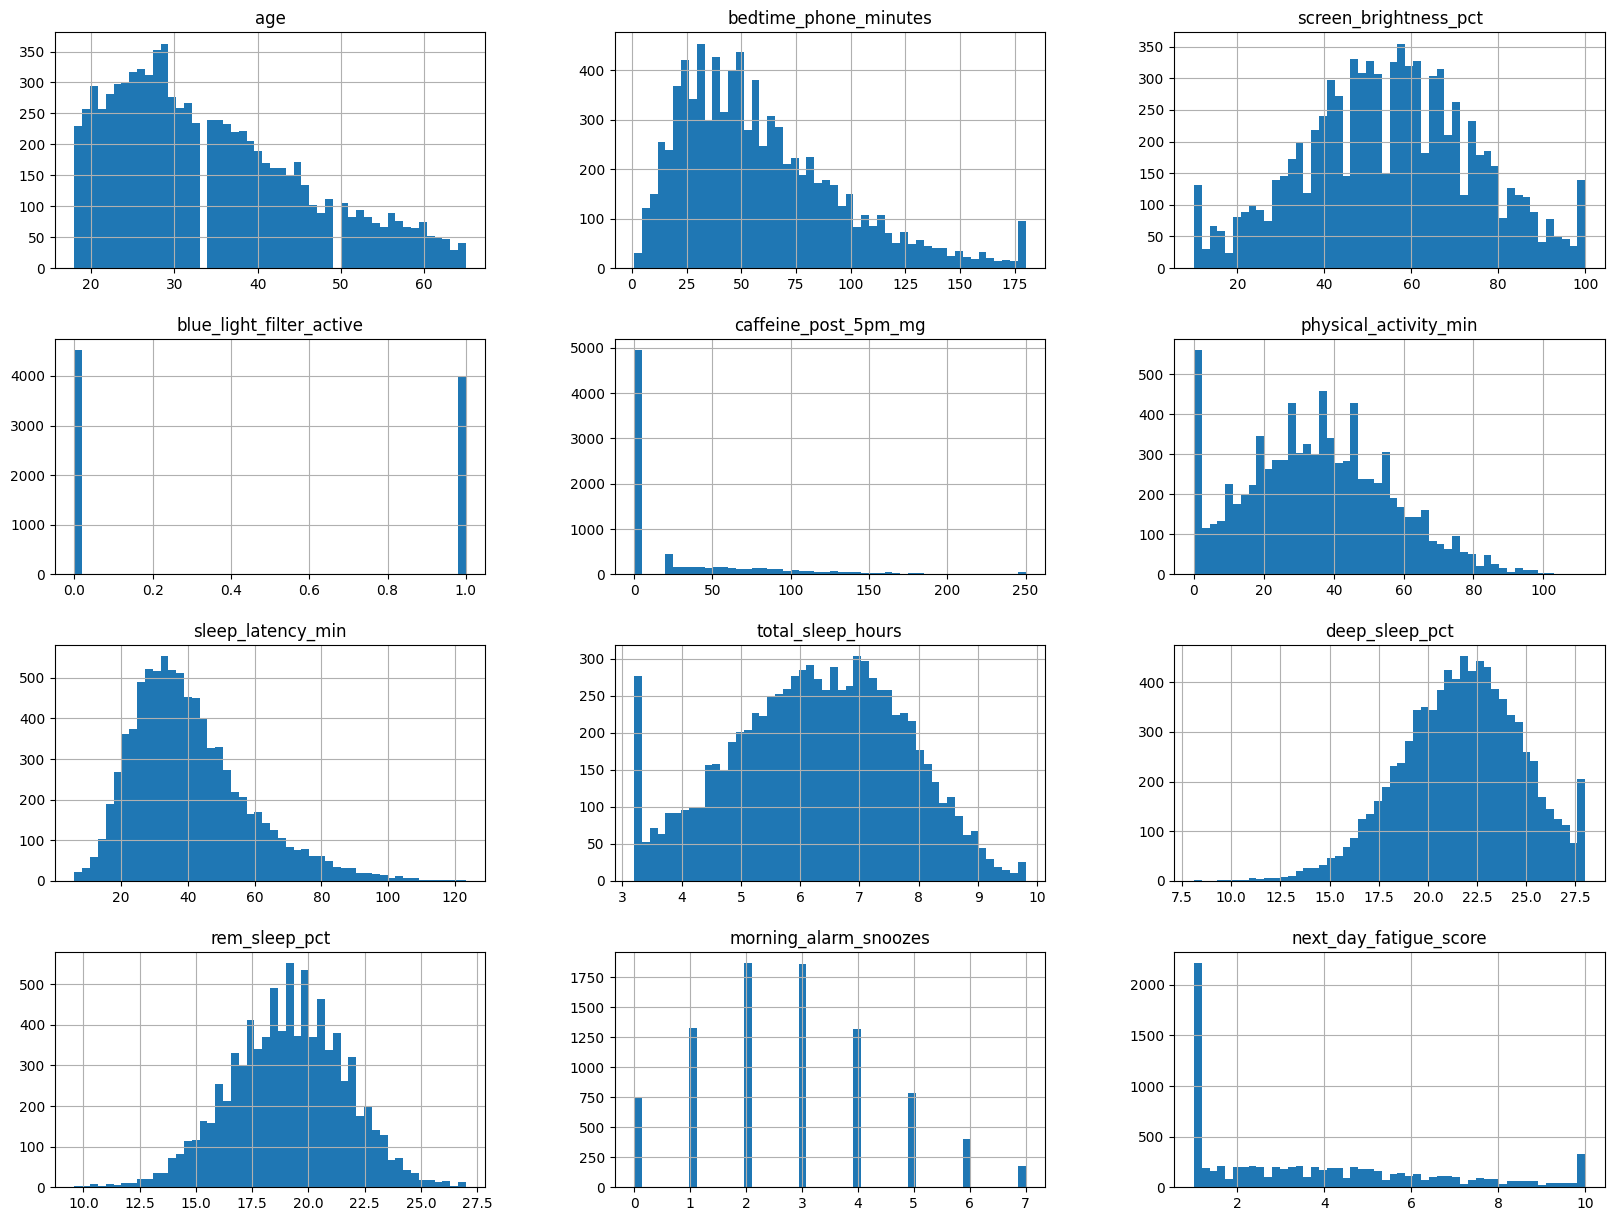

In [57]:
df.hist(bins=50,figsize=(20,15))

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'bedtime_phone_minutes'}>,
        <Axes: title={'center': 'screen_brightness_pct'}>],
       [<Axes: title={'center': 'blue_light_filter_active'}>,
        <Axes: title={'center': 'caffeine_post_5pm_mg'}>,
        <Axes: title={'center': 'physical_activity_min'}>],
       [<Axes: title={'center': 'sleep_latency_min'}>,
        <Axes: title={'center': 'total_sleep_hours'}>,
        <Axes: title={'center': 'deep_sleep_pct'}>],
       [<Axes: title={'center': 'rem_sleep_pct'}>,
        <Axes: title={'center': 'morning_alarm_snoozes'}>, <Axes: >]],
      dtype=object)

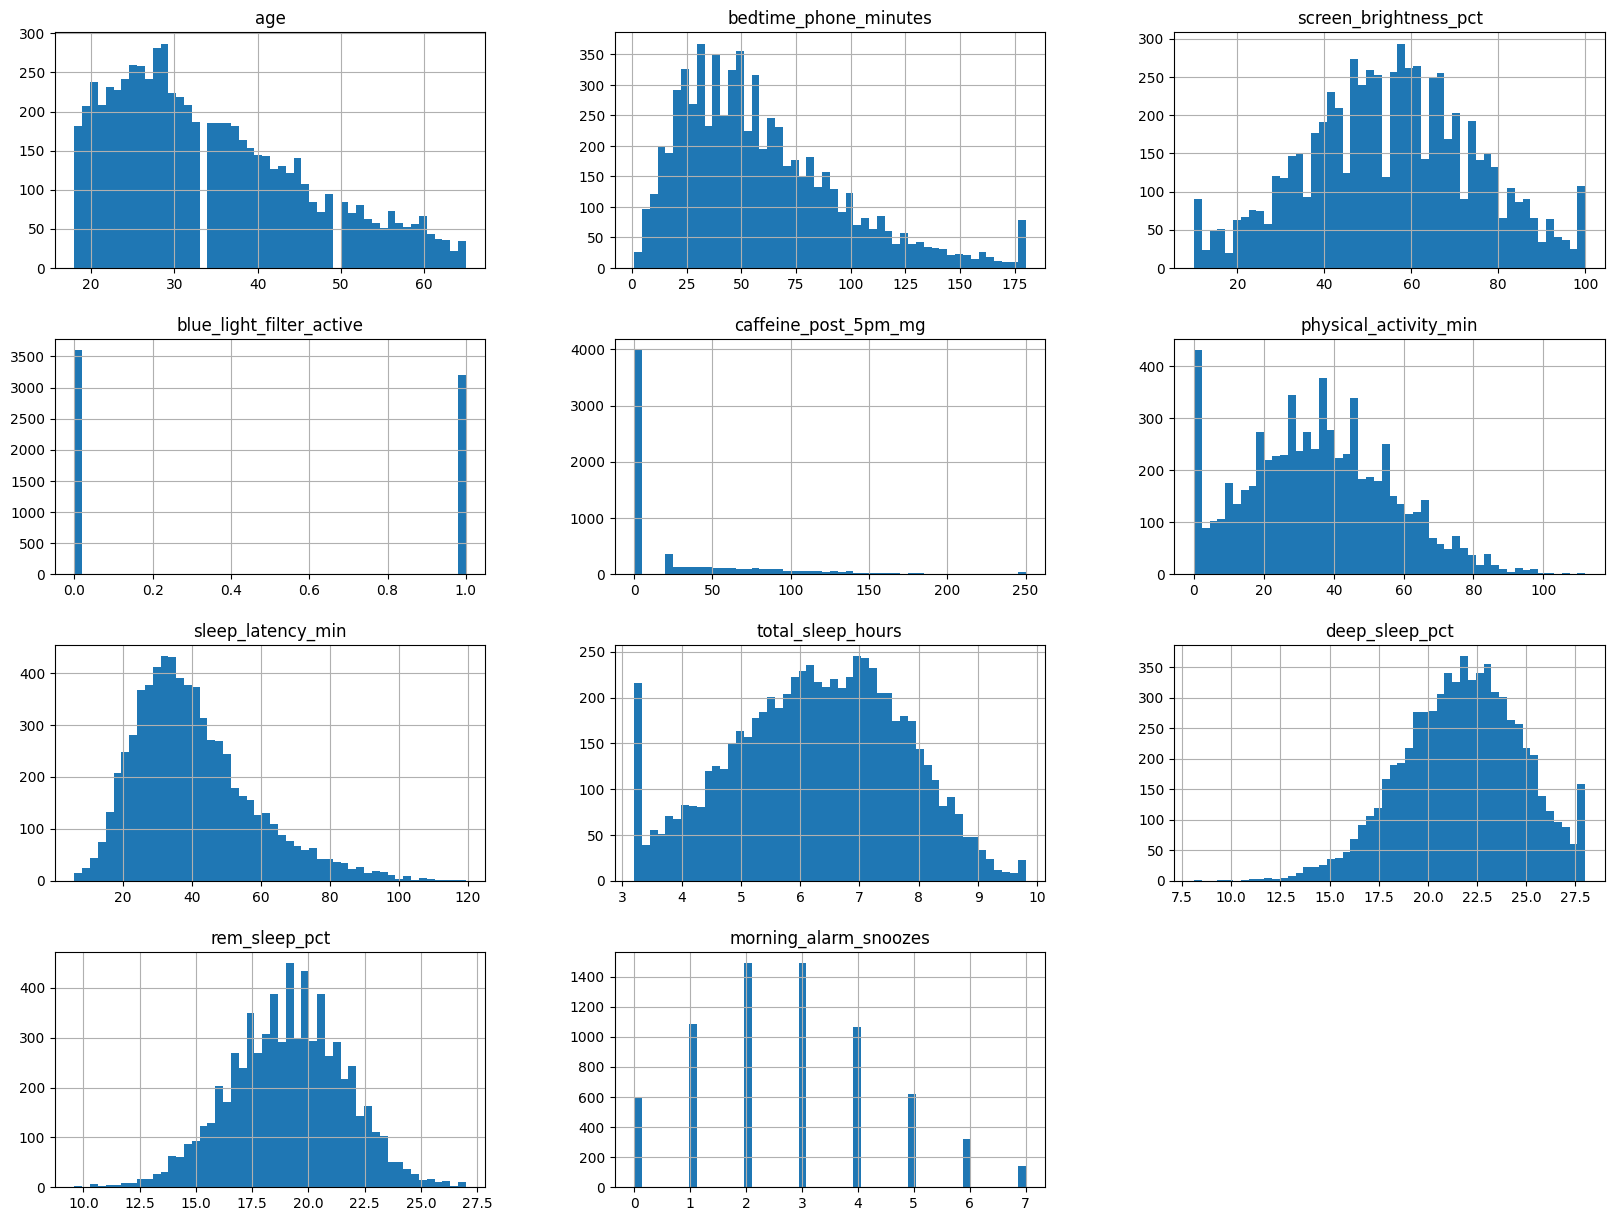

In [58]:
#x_train.hist(bins=50,figsize=(20,15))

In [6]:
y=df.iloc[:,16:17]
y

,next_day_fatigue_score
0,10.0
1,10.0
2,10.0
3,1.7
4,5.3
...,...
8495,3.2
8496,10.0
8497,3.7
8498,10.0


In [13]:

x=df.drop(columns=['user_id','next_day_fatigue_score'])
x


Output hidden; open in https://colab.research.google.com to view.

In [14]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [15]:
x_train

Output hidden; open in https://colab.research.google.com to view.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [16]:
num_cols = x_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_cols = x_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()



In [17]:
num_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])

cat_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])

#combine both pipeline

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

x_train_n=full_pipeline.fit_transform(x_train)
x_train_n

array([[-1.06450767,  0.75340379,  2.27509339, ...,  1.        ,
         0.        ,  0.        ],
       [ 2.28687932, -0.74105651, -0.41918271, ...,  1.        ,
         0.        ,  0.        ],
       [-1.40823967,  3.28040031,  0.59752525, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [-1.06450767,  0.18279168,  0.80086684, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.74008532, -0.1704444 , -0.21584112, ...,  0.        ,
         0.        ,  0.        ],
       [-0.63484267, -0.14327239,  0.85170224, ...,  0.        ,
         0.        ,  0.        ]])

In [18]:
print(x_train_n.shape)

(6800, 32)


In [19]:
print("Original features:", x_train.shape[1])
print("Transformed features:", x_train_n.shape[1])

print("\nUnique values in categorical columns:")

for col in cat_cols:
    print(col, ":", x_train[col].nunique())

Original features: 16
Transformed features: 32

Unique values in categorical columns:
gender : 3
occupation_type : 5
chronotype : 3
primary_bedtime_app : 6
sleep_debt_category : 4


###Linear Model

In [22]:
from sklearn.linear_model import LinearRegression
lin_reg=LinearRegression()
lin_reg.fit(x_train_n,y_train)

LinearRegression()

In [28]:
sd=x_train.iloc[:50]
sd2=y_train.iloc[:50]
sd_n=full_pipeline.fit_transform(sd)
print(f'Prediction\n{lin_reg.predict(sd_n)}')
print(f'Actual\n{sd2}')
#print(sd_n.shape)

Prediction
[[ 4.43314733]
 [ 4.9650565 ]
 [11.2184255 ]
 [ 2.03369178]
 [ 1.64605093]
 [ 3.39164948]
 [ 0.51983875]
 [ 4.07024909]
 [ 7.89404471]
 [ 7.56495286]
 [ 7.87039339]
 [ 2.31671489]
 [ 5.34042247]
 [ 4.40709791]
 [ 2.08670052]
 [ 0.98032231]
 [ 3.95660164]
 [ 1.25422476]
 [ 4.80461454]
 [ 2.59871003]
 [ 3.81974588]
 [ 3.74063856]
 [ 1.84564614]
 [ 2.3510715 ]
 [ 4.87347177]
 [ 5.76877265]
 [ 2.1915635 ]
 [ 6.41092694]
 [ 6.12651058]
 [ 6.10348147]
 [ 2.89381052]
 [ 0.64189705]
 [ 7.91425669]
 [ 6.18979737]
 [ 2.19015084]
 [ 3.11094047]
 [ 4.33703742]
 [-1.18596676]
 [ 2.05406531]
 [ 2.45856362]
 [ 0.60318981]
 [ 1.11759936]
 [ 4.1808575 ]
 [ 6.29205028]
 [ 2.2438198 ]
 [ 0.62247909]
 [ 1.22339202]
 [ 5.81844948]
 [ 6.07006981]
 [ 3.28316318]]
Actual
      next_day_fatigue_score
2706                     3.9
6263                     4.8
4687                    10.0
3966                     2.1
5441                     1.0
1047                     2.0
8329                     1.0

In [33]:
from sklearn.metrics import mean_squared_error
prediction=lin_reg.predict(sd_n)
lin_mse=mean_squared_error(prediction,sd2)
lin_rmse=np.sqrt(lin_mse)
print(lin_rmse)

0.8982029576923113


In [41]:
#cross val score
from sklearn.model_selection import cross_val_score
score=cross_val_score(
    lin_reg,x_train_n,y_train,cv=5,scoring='neg_mean_squared_error'
)
print(np.sqrt(-score))

[0.71289151 0.71673826 0.7033851  0.7140136  0.71481886]


###Random forest

In [44]:
from sklearn.ensemble import RandomForestRegressor
rf_reg=RandomForestRegressor(n_estimators=100,
                             min_samples_split=2,
                           random_state=42  )
rf_reg.fit(x_train_n,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestRegressor(random_state=42)

In [45]:
forest_prediction=rf_reg.predict(sd_n)
print(forest_prediction)
print(sd2)

[3.875 5.217 9.988 1.83  1.396 2.94  1.    3.59  7.856 7.841 7.8   2.326
 5.023 4.178 2.112 1.016 3.793 1.    4.497 1.394 3.5   3.897 1.415 1.129
 4.682 6.275 2.136 6.607 6.193 6.217 2.632 1.001 7.821 6.301 1.027 3.073
 4.33  1.    1.026 2.03  1.009 1.031 4.212 6.331 2.316 1.002 1.059 6.357
 6.454 3.099]
      next_day_fatigue_score
2706                     3.9
6263                     4.8
4687                    10.0
3966                     2.1
5441                     1.0
1047                     2.0
8329                     1.0
3534                     3.0
414                      7.6
6804                     7.1
7535                     8.2
8080                     1.9
5044                     3.6
4217                     3.3
2697                     1.9
7077                     1.0
3288                     4.3
2991                     1.0
2439                     3.8
5786                     1.0
5907                     3.0
1583                     2.5
1412                     1.

In [48]:
fp=rf_reg.predict(x_train_n)
forest_mse=mean_squared_error(fp,y_train )
forest_rmse=np.sqrt(forest_mse)
print(forest_rmse)

0.21800503400825674


In [49]:
#CROSS VAL
rf_score=cross_val_score(
    rf_reg,x_train_n,y_train,cv=5,scoring='neg_mean_squared_error'
)
print(np.sqrt(-rf_score))

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example usi

[0.58393007 0.59317624 0.58030028 0.60305943 0.58460183]


###DecisionTreeRegressor

In [50]:
from sklearn.tree import DecisionTreeRegressor
dt_reg=DecisionTreeRegressor(random_state=42)
dt_reg.fit(x_train_n,y_train)

DecisionTreeRegressor(random_state=42)

In [52]:
print(dt_reg.predict(sd_n))

print(sd2)

[ 3.9  5.2 10.   2.1  1.   2.   1.   4.8  7.9  8.   7.6  2.9  5.3  4.6
  1.8  1.   2.9  1.   4.2  1.   4.5  4.6  1.5  1.   4.4  7.8  3.4  6.7
  6.1  6.6  1.9  1.   7.8  6.4  1.   3.   5.2  1.   1.   2.8  1.   1.
  3.8  5.6  2.   1.   1.   5.3  5.9  2.6]
      next_day_fatigue_score
2706                     3.9
6263                     4.8
4687                    10.0
3966                     2.1
5441                     1.0
1047                     2.0
8329                     1.0
3534                     3.0
414                      7.6
6804                     7.1
7535                     8.2
8080                     1.9
5044                     3.6
4217                     3.3
2697                     1.9
7077                     1.0
3288                     4.3
2991                     1.0
2439                     3.8
5786                     1.0
5907                     3.0
1583                     2.5
1412                     1.5
8476                     1.0
7955                 

In [54]:
dt_prediction=dt_reg.predict(x_train_n)
dt_mse=mean_squared_error(dt_prediction,y_train)
print(np.sqrt(dt_mse))


5.2765660799459064e-17


In [55]:
#CROSSVAL
dt_score=cross_val_score(
    dt_reg,
    x_train_n,y_train,cv=5,scoring='neg_mean_squared_error'
)
print(np.sqrt(-dt_score))

[0.82768725 0.86358095 0.87113432 0.84619825 0.861646  ]


###Import model

In [59]:
import joblib
joblib.dump(rf_reg,'next_day_fatigue_score.pkl')
joblib.dump(full_pipeline,'NDFS_Pipeline.pkl')

['NDFS_Pipeline.pkl']